In [36]:
# Chapter 1 - Section 1: Configuration and dependencies
from __future__ import annotations

import importlib.util
import json
import sys
from pathlib import Path

def resolve_repo_root(start: Path) -> Path:
    """Resolve repository root from notebook location."""
    for candidate in [start, *start.parents]:
        if (candidate / "AGENTS.md").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Unable to resolve repository root")

NOTEBOOK_PATH = Path.cwd() / "03_consolidated_dataset_pipeline.ipynb"
if not NOTEBOOK_PATH.exists():
    NOTEBOOK_PATH = Path(__file__).resolve() if "__file__" in globals() else Path.cwd()

ROOT = resolve_repo_root(NOTEBOOK_PATH.resolve())
SCRIPT_PATH = ROOT / "scripts/stage2_consolidated_dataset_pipeline.py"

spec = importlib.util.spec_from_file_location("stage2_pipeline", SCRIPT_PATH)
if spec is None or spec.loader is None:
    raise RuntimeError("Unable to load stage2 pipeline module")
pipeline = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = pipeline
spec.loader.exec_module(pipeline)

print(json.dumps({"repo_root": str(ROOT), "pipeline_script": str(SCRIPT_PATH)}, indent=2))

{
  "repo_root": "/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2",
  "pipeline_script": "/Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/scripts/stage2_consolidated_dataset_pipeline.py"
}


In [37]:
# Chapter 1 - Section 2: Input and schema validation
paths = pipeline.build_paths(ROOT)
epi_columns = pipeline.validate_epi_headers(paths)
climate_columns = pipeline.validate_climate_header(paths)
catalog = pipeline.load_scope_catalog(paths)

summary = {
    "epi_column_count": len(epi_columns),
    "climate_column_count": len(climate_columns),
    "scope_municipality_count": int(catalog["municipality_code"].nunique()),
}
print(json.dumps(summary, indent=2))

{
  "epi_column_count": 69,
  "climate_column_count": 18,
  "scope_municipality_count": 76
}


In [38]:
# Chapter 1 - Section 3: Auxiliary normalization checks
sample = ["1", "001", "A2", ""]
normalized = [pipeline.normalize_numeric_code(value, 3) for value in sample]
print(json.dumps({"sample": sample, "normalized": normalized}, indent=2))

{
  "sample": [
    "1",
    "001",
    "A2",
    ""
  ],
  "normalized": [
    "001",
    "001",
    "",
    ""
  ]
}


In [39]:
# Chapter 1 - Section 4: Individual consolidation execution
config = pipeline.PipelineConfig(
    chunksize_epi=200_000,
    chunksize_climate=250_000,
    contract_version="candidate-construction-v1",
    perform_safe_write=True,
)
result = pipeline.run_pipeline(root=ROOT, config=config)
print(json.dumps({
    "consolidated_path": str(result.consolidated_path.relative_to(ROOT)),
    "panel_path": str(result.panel_path.relative_to(ROOT)),
    "consolidated_rows": result.consolidated_rows,
    "panel_rows": result.panel_rows,
}, indent=2))

{
  "consolidated_path": "data/processed/dengue_y_dengue_grave.csv",
  "panel_path": "data/processed/panel_mensual_dengue_clima.csv",
  "consolidated_rows": 1755705,
  "panel_rows": 17936
}


In [40]:
# Chapter 1 - Section 5: Daily climate join audit
manifest_path = ROOT / "data/interim/stage2_consolidated_dataset_pipeline/execution_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
join_audit = {
    "no_climate_match_assignable_rows": manifest["reconciliation"]["no_climate_match_assignable_rows"],
    "outside_scope_rows": manifest["reconciliation"]["outside_scope_rows"],
    "missing_or_unparseable_onset_rows": manifest["reconciliation"]["missing_or_unparseable_onset_rows"],
}
print(json.dumps(join_audit, indent=2))

{
  "no_climate_match_assignable_rows": 112,
  "outside_scope_rows": 1515860,
  "missing_or_unparseable_onset_rows": 136
}


In [41]:
# Chapter 1 - Section 6: Monthly panel inspection
panel_path = ROOT / "data/processed/panel_mensual_dengue_clima.csv"
panel = pipeline.pd.read_csv(panel_path)
panel_summary = {
    "rows": int(len(panel)),
    "columns": int(len(panel.columns)),
    "unique_municipalities": int(panel["municipality_code"].nunique()),
    "month_min": str(panel["year_month"].min()),
    "month_max": str(panel["year_month"].max()),
    "zero_in_coverage_rows": int((panel["epi_count_status"] == "zero_in_coverage").sum()),
    "outside_coverage_missing_rows": int((panel["epi_count_status"] == "outside_epi_coverage_missing").sum()),
}
for horizon in (1, 2):
    suffix = f"t{horizon}"
    evaluable_col = f"y_evaluable_{suffix}"
    status_col = f"y_status_{suffix}"
    label_col = f"y_{suffix}"
    if evaluable_col in panel.columns and status_col in panel.columns and label_col in panel.columns:
        panel_summary[f"{suffix}_evaluable_rows"] = int(panel[evaluable_col].fillna(False).sum())
        panel_summary[f"{suffix}_non_evaluable_rows"] = int((~panel[evaluable_col].fillna(False)).sum())
        panel_summary[f"{suffix}_status_counts"] = {
            str(key): int(value)
            for key, value in panel[status_col].value_counts(dropna=False).items()
        }
        panel_summary[f"{suffix}_label_counts"] = {
            ("NA" if pipeline.pd.isna(key) else str(int(key))): int(value)
            for key, value in panel[label_col].value_counts(dropna=False).items()
        }
print(json.dumps(panel_summary, indent=2))

{
  "rows": 17936,
  "columns": 47,
  "unique_municipalities": 76,
  "month_min": "2006-06",
  "month_max": "2026-01",
  "zero_in_coverage_rows": 6263,
  "outside_coverage_missing_rows": 0,
  "t1_evaluable_rows": 13376,
  "t1_non_evaluable_rows": 4560,
  "t1_status_counts": {
    "evaluable": 13376,
    "insufficient_history": 4484,
    "target_outside_panel": 76
  },
  "t1_label_counts": {
    "0": 8930,
    "NA": 4560,
    "1": 4446
  },
  "t2_evaluable_rows": 13376,
  "t2_non_evaluable_rows": 4560,
  "t2_status_counts": {
    "evaluable": 13376,
    "insufficient_history": 4408,
    "target_outside_panel": 152
  },
  "t2_label_counts": {
    "0": 8930,
    "NA": 4560,
    "1": 4446
  }
}


In [42]:
# Chapter 1 - Section 7: Reconciliation and validations
validator_path = ROOT / ".dwp/plans/PLAN_014_stage2_y_labels/validate_y_outputs.py"
validator_spec = importlib.util.spec_from_file_location("validator", validator_path)
if validator_spec is None or validator_spec.loader is None:
    raise RuntimeError("Unable to load validation module")
validator = importlib.util.module_from_spec(validator_spec)
sys.modules[validator_spec.name] = validator
validator_spec.loader.exec_module(validator)
validation_report = validator.validate_quick(ROOT, pipeline)
print(json.dumps(validation_report, indent=2))

{
  "consolidated_rows": 1755705,
  "panel_rows": 17936,
  "traceability_rows": 35872,
  "consolidated_sha256": "315a43aab561fa29a45c657c635c511b201847ca530eae0285e1522b2f7942ed",
  "panel_sha256": "907efacb8e044a400bd1aca4cb2b96f9e3fad6705df0e22fe320f25fb573b2fe",
  "traceability_sha256": "c99aad6cf87fb8b0dba46f9468b5ba2ff9c7a5957baea988109a39650339de03",
  "horizons": {
    "t1": {
      "evaluable_rows": 13376,
      "non_evaluable_rows": 4560,
      "positive_labels": 4446
    },
    "t2": {
      "evaluable_rows": 13376,
      "non_evaluable_rows": 4560,
      "positive_labels": 4446
    }
  }
}


In [43]:
# Chapter 1 - Section 8: Safe write outputs and execution summary
contract_path = ROOT / "data/interim/stage2_consolidated_dataset_pipeline/candidate_construction_contract_v1.json"
contract = json.loads(contract_path.read_text(encoding="utf-8"))
summary = {
    "candidate_contract_version": contract["contract_version"],
    "classification": contract["classification"],
    "y_labeling_policy": contract.get("target_labeling_policy", {}),
    "manifest_path": "data/interim/stage2_consolidated_dataset_pipeline/execution_manifest.json",
    "consolidated_csv": "data/processed/dengue_y_dengue_grave.csv",
    "panel_csv": "data/processed/panel_mensual_dengue_clima.csv",
    "y_traceability_csv": "data/interim/stage2_consolidated_dataset_pipeline/y_label_history_traceability.csv",
}
print(json.dumps(summary, indent=2))

{
  "candidate_contract_version": "candidate-construction-v1",
  "classification": "candidate_construction_contract",
  "y_labeling_policy": {
    "series": "dengue_notifications_count",
    "horizons_months": [
      1,
      2
    ],
    "reference_years": 5,
    "seasonality_basis": "same_calendar_month",
    "historical_reference_rule": "For target period YYYY-MM, use the same MM from the five prior years (YYYY-5..YYYY-1) without substituting older years when a required observation is genuinely missing.",
    "decision_rule": "label_1_if_observed_strictly_greater_than_p75",
    "non_evaluable_rule": "missing_future_or_insufficient_history_yields_null_label",
    "percentile": 0.75,
    "percentile_method": "hyndman_fan_type7_linear"
  },
  "manifest_path": "data/interim/stage2_consolidated_dataset_pipeline/execution_manifest.json",
  "consolidated_csv": "data/processed/dengue_y_dengue_grave.csv",
  "panel_csv": "data/processed/panel_mensual_dengue_clima.csv",
  "y_traceability_csv"

In [57]:
# Chapter 2 - Common temporal preparation and shared analysis state
from __future__ import annotations

import hashlib
import importlib.util

import numpy as np
import pandas as pd
from IPython.display import display

ANALYSIS_DIR = ROOT / "tmp/stage2_y_reconciliation"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Ensure deterministic evidence artifacts by removing stale files from prior runs.
for artifact in ANALYSIS_DIR.glob("*"):
    if artifact.is_file():
        artifact.unlink()

# Shared analysis module import for DRY notebook sections.
VISUAL_ASSETS_PATH = ROOT / "scripts/stage2_notebook_visual_assets.py"
visual_spec = importlib.util.spec_from_file_location("stage2_visual_assets", VISUAL_ASSETS_PATH)
if visual_spec is None or visual_spec.loader is None:
    raise RuntimeError("Unable to load visual-assets helper module")
visual_assets = importlib.util.module_from_spec(visual_spec)
sys.modules[visual_spec.name] = visual_assets
visual_spec.loader.exec_module(visual_assets)

panel_path = ROOT / "data/processed/panel_mensual_dengue_clima.csv"
panel_analysis = pd.read_csv(panel_path)

required_y_columns = {
    "y_t1",
    "y_t2",
    "y_status_t1",
    "y_status_t2",
    "y_evaluable_t1",
    "y_evaluable_t2",
}
missing_y_columns = sorted(required_y_columns - set(panel_analysis.columns))
if missing_y_columns:
    raise RuntimeError(f"Panel is missing Y prerequisites: {missing_y_columns}")

panel_analysis = panel_analysis.sort_values(["municipality_code", "year_month"]).reset_index(drop=True)

month_max = str(panel_analysis["year_month"].max())
reserved_block_start = "2025-01"
development_end = "2024-12"

if month_max < reserved_block_start:
    raise RuntimeError("Reserved temporal block is not available in current panel")

panel_analysis["is_development"] = panel_analysis["year_month"].between(
    str(panel_analysis["year_month"].min()),
    development_end,
)
panel_analysis["is_reserved_block"] = panel_analysis["year_month"].between(
    reserved_block_start,
    month_max,
)

if bool((panel_analysis["is_development"] & panel_analysis["is_reserved_block"]).any()):
    raise RuntimeError("Temporal split overlap detected")

panel_development = panel_analysis[panel_analysis["is_development"]].copy()
panel_reserved = panel_analysis[panel_analysis["is_reserved_block"]].copy()

# Shared variable specifications for Table 1 (missingness and continuity).
variable_specs = [
    visual_assets.VariableSpec("dengue_notifications_count", "cases", "epi_coverage"),
    visual_assets.VariableSpec("dengue_grave_notifications_count", "cases", "epi_coverage"),
    visual_assets.VariableSpec("rain_mm_month_sum", "mm", "climate_expected_days"),
    visual_assets.VariableSpec("surface_runoff_mm_month_sum", "mm", "climate_expected_days"),
    visual_assets.VariableSpec("total_evaporation_mm_month_sum_ecmwf", "mm", "climate_expected_days"),
    visual_assets.VariableSpec("solar_radiation_mj_m2_month_sum", "MJ/m2", "climate_expected_days"),
    visual_assets.VariableSpec("temp_mean_c_month_mean", "C", "climate_expected_days"),
    visual_assets.VariableSpec("dewpoint_mean_c_month_mean", "C", "climate_expected_days"),
    visual_assets.VariableSpec("soil_water_l1_month_mean", "m3/m3", "climate_expected_days"),
    visual_assets.VariableSpec("wind_u_ms_month_mean", "m/s", "climate_expected_days"),
    visual_assets.VariableSpec("wind_v_ms_month_mean", "m/s", "climate_expected_days"),
    visual_assets.VariableSpec("y_t1", "binary", "y_evaluable_t1"),
    visual_assets.VariableSpec("y_t2", "binary", "y_evaluable_t2"),
]

# Shared predictor family setup for Figure 2 lag associations.
predictor_specs = [
    visual_assets.PredictorSpec("Epidemiological history", "dengue_notifications_count", "dengue_notifications", (1, 2, 3)),
    visual_assets.PredictorSpec("Epidemiological history", "dengue_grave_notifications_count", "dengue_grave_notifications", (1, 2)),
    visual_assets.PredictorSpec("Climate", "rain_mm_month_sum", "rain_mm", (1, 2)),
    visual_assets.PredictorSpec("Climate", "temp_mean_c_month_mean", "temp_mean_c", (1, 2)),
    visual_assets.PredictorSpec("Climate", "dewpoint_mean_c_month_mean", "dewpoint_mean_c", (1,)),
    visual_assets.PredictorSpec("Climate", "surface_runoff_mm_month_sum", "surface_runoff_mm", (1,)),
    visual_assets.PredictorSpec("Derived", "climate_days_observed", "climate_days_observed", (1,)),
]
predictor_specs = [spec for spec in predictor_specs if spec.base_column in panel_development.columns]
predictor_columns_used = sorted({spec.base_column for spec in predictor_specs})

presentation_requirements = {
    "new_tables": 2,
    "new_figures": 2,
}

chapter2_summary = {
    "dataset": "panel_mensual_dengue_clima",
    "rows_total": int(len(panel_analysis)),
    "rows_development": int(len(panel_development)),
    "rows_reserved_block": int(len(panel_reserved)),
    "municipalities": int(panel_analysis["municipality_code"].nunique()),
    "development_start": str(panel_development["year_month"].min()),
    "development_end": str(panel_development["year_month"].max()),
    "reserved_block_start": str(panel_reserved["year_month"].min()),
    "reserved_block_end": str(panel_reserved["year_month"].max()),
    "presentation_requirements": presentation_requirements,
    "retrospective_data_limitation": (
        "Temporal ordering is computed on consolidated retrospective data and does not prove "
        "historical operational as-of availability snapshots."
    ),
}

(ANALYSIS_DIR / "chapter2_temporal_preparation.json").write_text(
    json.dumps(chapter2_summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(chapter2_summary, indent=2, ensure_ascii=False))

{
  "dataset": "panel_mensual_dengue_clima",
  "rows_total": 17936,
  "rows_development": 16948,
  "rows_reserved_block": 988,
  "municipalities": 76,
  "development_start": "2006-06",
  "development_end": "2024-12",
  "reserved_block_start": "2025-01",
  "reserved_block_end": "2026-01",
  "presentation_requirements": {
    "new_tables": 2,
    "new_figures": 2
  },
  "retrospective_data_limitation": "Temporal ordering is computed on consolidated retrospective data and does not prove historical operational as-of availability snapshots."
}


In [58]:
# Chapter 3 - Missingness analysis and handling proposals
missingness_full, missingness_compact, missingness_denominators = visual_assets.build_missingness_inventory(
    panel_development,
    variable_specs,
    top_k=10,
)

proposal_rows = [
    {
        "variable": "dengue_notifications_count",
        "evidence": "Coverage-aware monthly counts with explicit zero_in_coverage status",
        "affected_population": "All municipalities and months in development split",
        "proposal": "Do not impute target-side observations; preserve explicit status columns",
        "limitations": "Retrospective consolidated dataset cannot certify real-time publication snapshots",
    },
    {
        "variable": "climate monthly aggregates",
        "evidence": "Coverage counters and valid-day checks are available by variable",
        "affected_population": "Rows with incomplete climate-day coverage",
        "proposal": "Keep missing as missing; evaluate model-side imputation in derived copies only",
        "limitations": "No generalized imputation rule is approved in this stage",
    },
    {
        "variable": "y_t1 and y_t2",
        "evidence": "Explicit evaluability and status columns",
        "affected_population": "Non-evaluable horizons",
        "proposal": "Never coerce non-evaluable Y labels to zero",
        "limitations": "Historical availability constraints remain retrospective",
    },
]
proposal_table = pd.DataFrame(proposal_rows)

missingness_full.to_csv(ANALYSIS_DIR / "chapter3_missingness_summary.csv", index=False)
missingness_compact.to_csv(ANALYSIS_DIR / "chapter3_table1_missingness_compact.csv", index=False)
proposal_table.to_csv(ANALYSIS_DIR / "chapter3_missingness_proposals.csv", index=False)
(ANALYSIS_DIR / "chapter3_missingness_denominators.json").write_text(
    json.dumps(missingness_denominators, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

# Presentation Table 1 - Missingness and continuity (compact deterministic selection)
table1_columns = [
    "variable",
    "unit",
    "expected_eligible_rows",
    "missing_rows",
    "missing_pct",
    "affected_municipalities",
    "longest_missing_gap_months",
    "longest_gap_municipality",
    "longest_gap_period_start",
    "longest_gap_period_end",
    "absence_type",
]
table1_view = missingness_compact[table1_columns].copy()
table1_view["missing_pct"] = (table1_view["missing_pct"] * 100.0).round(2)
display(table1_view)

print(
    "Table 1 denominator note: eligible rows are computed per variable rule. "
    "Climate denominator uses in_epi_coverage rows; Y uses y_evaluable_t1/t2 only. "
    "Selection is deterministic by impact_score and full inventory is exported."
)

chapter3_summary = {
    "development_rows": int(len(panel_development)),
    "full_inventory_rows": int(len(missingness_full)),
    "compact_rows_displayed": int(len(missingness_compact)),
    "denominator_rules": {
        key: value["eligible_rule"]
        for key, value in missingness_denominators["variable_denominators"].items()
    },
}

(ANALYSIS_DIR / "chapter3_missingness_summary.json").write_text(
    json.dumps(chapter3_summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(chapter3_summary, indent=2, ensure_ascii=False))

,variable,unit,expected_eligible_rows,missing_rows,missing_pct,affected_municipalities,longest_missing_gap_months,longest_gap_municipality,longest_gap_period_start,longest_gap_period_end,absence_type
0,dewpoint_mean_c_month_mean,C,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
1,rain_mm_month_sum,mm,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
2,soil_water_l1_month_mean,m3/m3,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
3,solar_radiation_mj_m2_month_sum,MJ/m2,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
4,surface_runoff_mm_month_sum,mm,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
5,temp_mean_c_month_mean,C,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
6,total_evaporation_mm_month_sum_ecmwf,mm,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
7,wind_u_ms_month_mean,m/s,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
8,wind_v_ms_month_mean,m/s,16948,532,3.14,76,7,50001,2006-06,2006-12,eligible_missing_in_coverage
9,dengue_grave_notifications_count,cases,16948,0,0.00,0,0,NaN,NaN,NaN,no_missing_in_eligible_scope


Table 1 denominator note: eligible rows are computed per variable rule. Climate denominator uses in_epi_coverage rows; Y uses y_evaluable_t1/t2 only. Selection is deterministic by impact_score and full inventory is exported.
{
  "development_rows": 16948,
  "full_inventory_rows": 13,
  "compact_rows_displayed": 10,
  "denominator_rules": {
    "dengue_notifications_count": "epi_coverage",
    "dengue_grave_notifications_count": "epi_coverage",
    "rain_mm_month_sum": "climate_expected_days",
    "surface_runoff_mm_month_sum": "climate_expected_days",
    "total_evaporation_mm_month_sum_ecmwf": "climate_expected_days",
    "solar_radiation_mj_m2_month_sum": "climate_expected_days",
    "temp_mean_c_month_mean": "climate_expected_days",
    "dewpoint_mean_c_month_mean": "climate_expected_days",
    "soil_water_l1_month_mean": "climate_expected_days",
    "wind_u_ms_month_mean": "climate_expected_days",
    "wind_v_ms_month_mean": "climate_expected_days",
    "y_t1": "y_evaluable_t1",
  

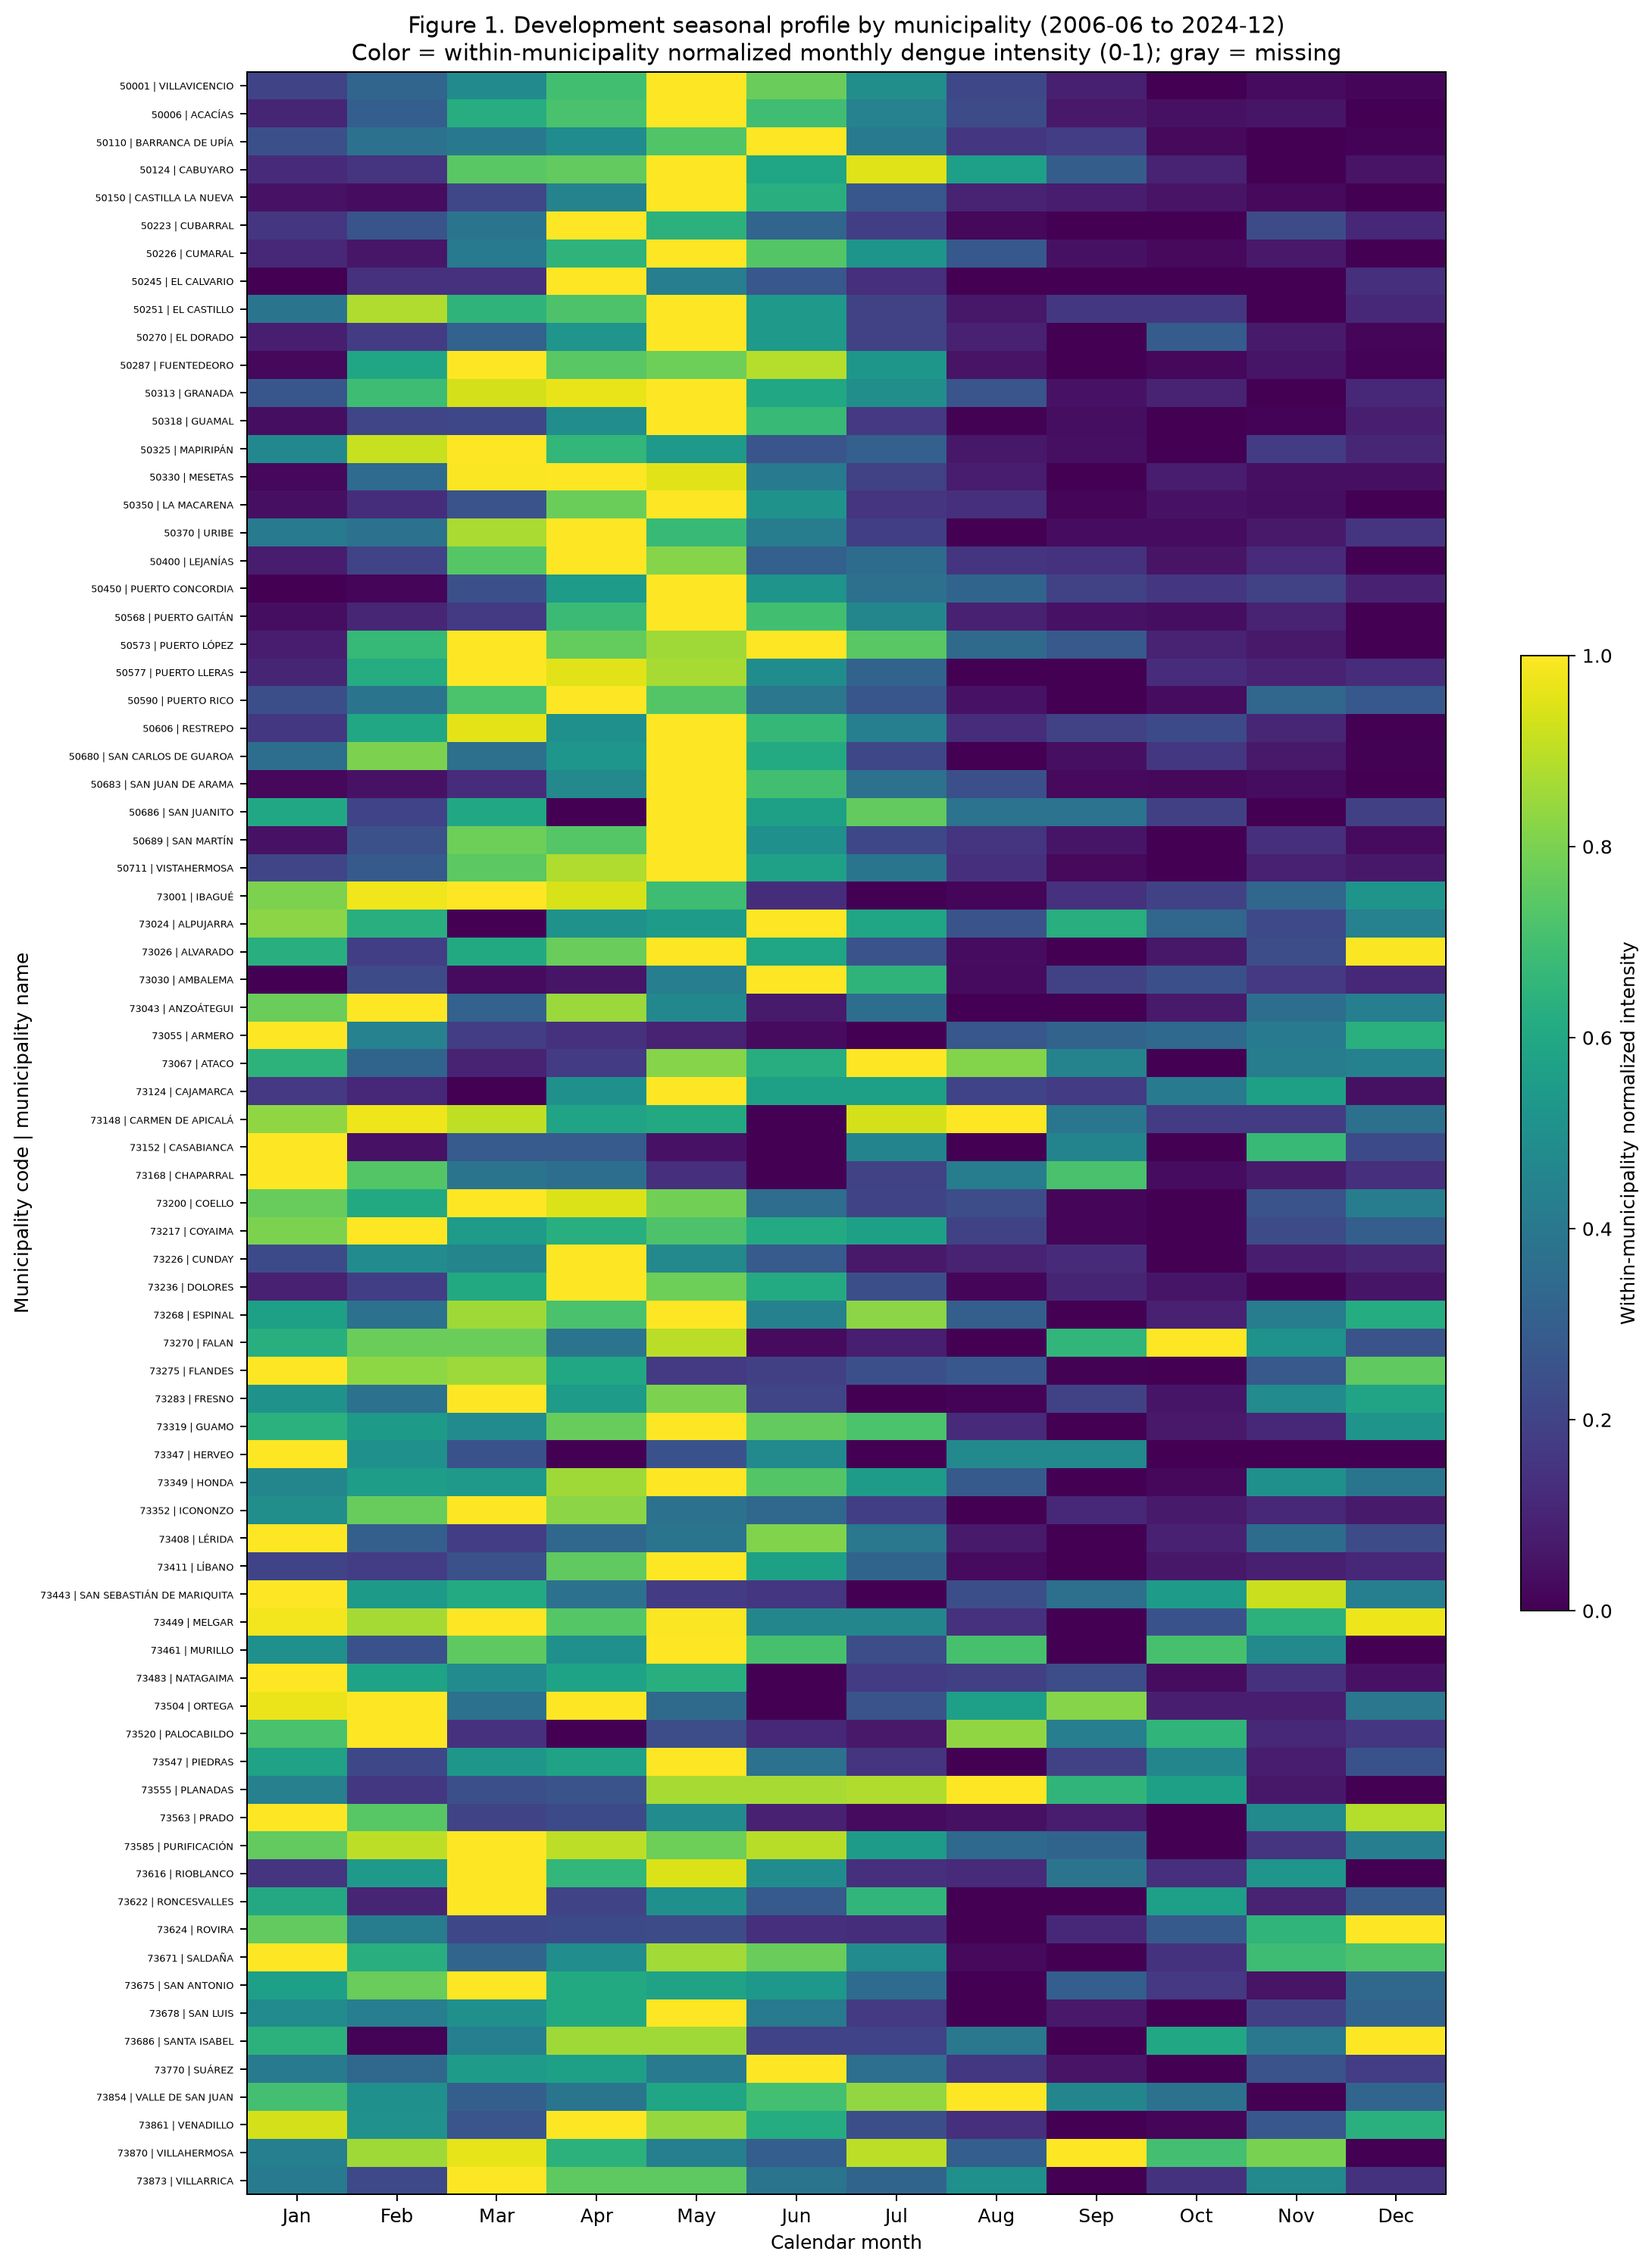

{
  "distribution_variables": 6,
  "municipalities": 76,
  "months": 12,
  "normalization_method": "within_municipality_minmax_with_constant_handling",
  "constant_nonzero_value": 0.5,
  "figure_outputs": [
    "tmp/stage2_y_reconciliation/chapter4_figure1_municipality_seasonality.png",
    "tmp/stage2_y_reconciliation/chapter4_figure1_municipality_seasonality.svg"
  ]
}


In [59]:
# Chapter 4 - Distributions, trends and seasonality diagnostics
import matplotlib.pyplot as plt

numeric_focus = [
    "dengue_notifications_count",
    "dengue_grave_notifications_count",
    "rain_mm_month_sum",
    "temp_mean_c_month_mean",
    "dewpoint_mean_c_month_mean",
    "surface_runoff_mm_month_sum",
]

distribution_rows = []
for column in numeric_focus:
    if column not in panel_development.columns:
        continue
    series = pd.to_numeric(panel_development[column], errors="coerce").dropna()
    if series.empty:
        continue
    distribution_rows.append(
        {
            "variable": column,
            "count": int(series.shape[0]),
            "mean": float(series.mean()),
            "std": float(series.std(ddof=0)),
            "p05": float(series.quantile(0.05)),
            "p25": float(series.quantile(0.25)),
            "p50": float(series.quantile(0.50)),
            "p75": float(series.quantile(0.75)),
            "p95": float(series.quantile(0.95)),
            "zero_count": int((series == 0).sum()),
        }
    )

distribution_summary = pd.DataFrame(distribution_rows)

seasonality_matrix, seasonality_raw_profile, seasonality_support, seasonality_meta = (
    visual_assets.compute_municipality_seasonality(
        panel_development,
        value_column="dengue_notifications_count",
    )
)

# Presentation Figure 1 - Municipality seasonality heatmap (normalized within municipality)
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
masked = np.ma.masked_invalid(seasonality_matrix.to_numpy(dtype=float))
cmap = plt.colormaps["viridis"].copy()
cmap.set_bad("#d9d9d9")

figure_height = max(10.0, 0.22 * len(seasonality_matrix))
fig, ax = plt.subplots(figsize=(13, figure_height), dpi=180)
image = ax.imshow(
    masked,
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    vmin=0.0,
    vmax=1.0,
)
ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)
ax.set_yticks(np.arange(len(seasonality_matrix.index)))
ax.set_yticklabels(seasonality_matrix.index, fontsize=5)
ax.set_xlabel("Calendar month")
ax.set_ylabel("Municipality code | municipality name")
ax.set_title(
    "Figure 1. Development seasonal profile by municipality "
    f"({chapter2_summary['development_start']} to {chapter2_summary['development_end']})\n"
    "Color = within-municipality normalized monthly dengue intensity (0-1); gray = missing"
)
colorbar = fig.colorbar(image, ax=ax, shrink=0.45)
colorbar.set_label("Within-municipality normalized intensity")
fig.tight_layout()

figure1_png = ANALYSIS_DIR / "chapter4_figure1_municipality_seasonality.png"
figure1_svg = ANALYSIS_DIR / "chapter4_figure1_municipality_seasonality.svg"
fig.savefig(figure1_png, dpi=220)
fig.savefig(figure1_svg)
plt.show()
plt.close(fig)

# Auxiliary evidence exports (not displayed as additional figures/tables).
seasonality_raw_profile.to_csv(ANALYSIS_DIR / "chapter4_seasonality_profile_raw.csv", index=False)
seasonality_support.to_csv(ANALYSIS_DIR / "chapter4_seasonality_support.csv", index=False)
(ANALYSIS_DIR / "chapter4_seasonality_meta.json").write_text(
    json.dumps(seasonality_meta, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
distribution_summary.to_csv(ANALYSIS_DIR / "chapter4_distribution_summary.csv", index=False)

chapter4_summary = {
    "distribution_variables": int(len(distribution_summary)),
    "municipalities": int(len(seasonality_matrix.index)),
    "months": 12,
    "normalization_method": seasonality_meta["normalization"],
    "constant_nonzero_value": seasonality_meta["constant_nonzero_value"],
    "figure_outputs": [
        str(figure1_png.relative_to(ROOT)),
        str(figure1_svg.relative_to(ROOT)),
    ],
}

(ANALYSIS_DIR / "chapter4_summary.json").write_text(
    json.dumps(chapter4_summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(chapter4_summary, indent=2, ensure_ascii=False))

In [60]:
# Chapter 5 - Cardinality, categories and 69-column matrix
raw_header = pipeline.validate_epi_headers(paths)

sample_size = 150_000
raw_sample = pd.read_csv(
    ROOT / "data/raw/dengue.csv",
    dtype=str,
    usecols=raw_header,
    nrows=sample_size,
    keep_default_na=False,
)

role_overrides = {
    "CONSECUTIVE": "identifier_traceability",
    "COD_DPTO_R": "geography",
    "COD_MUN_R": "geography",
    "INI_SIN": "time",
    "FEC_NOT": "time",
    "SEMANA": "time",
    "EDAD": "numeric_measure",
    "UNI_MED": "epidemiological_category",
    "TIP_CAS": "epidemiological_category",
    "AJUSTE": "epidemiological_category",
}

matrix_rows = []
for column in raw_header:
    sample_series = raw_sample[column].astype(str)
    non_empty = sample_series.str.strip().ne("")
    observed_non_empty = int(non_empty.sum())
    sample_cardinality = int(sample_series[non_empty].nunique())
    role = role_overrides.get(column, "underdocumented_field")

    if role == "identifier_traceability":
        transformation = "do_not_aggregate"
        disposition = "keep_as_provenance_only"
    elif role == "geography":
        transformation = "normalize_then_join_by_divipola"
        disposition = "keep_with_validation"
    elif role == "time":
        transformation = "parse_to_month_period"
        disposition = "keep_with_strict_parsing"
    elif role == "numeric_measure":
        transformation = "unit-aware_numeric_transformation"
        disposition = "evaluate_monthly_aggregation"
    elif role == "epidemiological_category":
        transformation = "frequency_and_drift_monitoring"
        disposition = "keep_as_candidate_predictor"
    else:
        transformation = "semantic_mapping_required_before_modeling"
        disposition = "review_before_use"

    matrix_rows.append(
        {
            "column_name": column,
            "semantic_group": role,
            "sample_non_empty_rows": observed_non_empty,
            "sample_cardinality": sample_cardinality,
            "quality_note": (
                "sample_based_profile_only; full profiling deferred to bounded tasks"
            ),
            "temporal_availability": "retrospective_consolidated_source",
            "current_use_in_pipeline": (
                "retained_in_consolidated_output"
                if column in raw_header
                else "not_applicable"
            ),
            "potential_monthly_transformation": transformation,
            "proposed_disposition": disposition,
            "justification": (
                "Stage 2 candidate evaluation without deleting original columns"
            ),
            "source_document": "data/raw/dengue.csv and docs/product/traking-concluciones.md",
        }
    )

column_matrix = pd.DataFrame(matrix_rows)

category_focus = [
    column
    for column in ["TIP_CAS", "AJUSTE", "UNI_MED", "SEMANA", "COD_DPTO_R", "COD_MUN_R"]
    if column in raw_sample.columns
]
category_profiles = []
for column in category_focus:
    freq = raw_sample[column].astype(str).str.strip().value_counts(dropna=False).head(25)
    for value, count in freq.items():
        category_profiles.append(
            {
                "column": column,
                "value": value,
                "count": int(count),
                "ratio": float(count / len(raw_sample)),
            }
        )

category_profile_table = pd.DataFrame(category_profiles)

column_matrix.to_csv(ANALYSIS_DIR / "chapter5_column_matrix.csv", index=False)
category_profile_table.to_csv(ANALYSIS_DIR / "chapter5_category_profiles.csv", index=False)

chapter5_summary = {
    "raw_column_count": len(raw_header),
    "sample_rows_profiled": sample_size,
    "semantic_groups": column_matrix["semantic_group"].value_counts().to_dict(),
    "matrix_path": "tmp/stage2_y_reconciliation/chapter5_column_matrix.csv",
}

(ANALYSIS_DIR / "chapter5_summary.json").write_text(
    json.dumps(chapter5_summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(chapter5_summary, indent=2, ensure_ascii=False))

{
  "raw_column_count": 69,
  "sample_rows_profiled": 150000,
  "semantic_groups": {
    "underdocumented_field": 59,
    "time": 3,
    "epidemiological_category": 3,
    "geography": 2,
    "identifier_traceability": 1,
    "numeric_measure": 1
  },
  "matrix_path": "tmp/stage2_y_reconciliation/chapter5_column_matrix.csv"
}


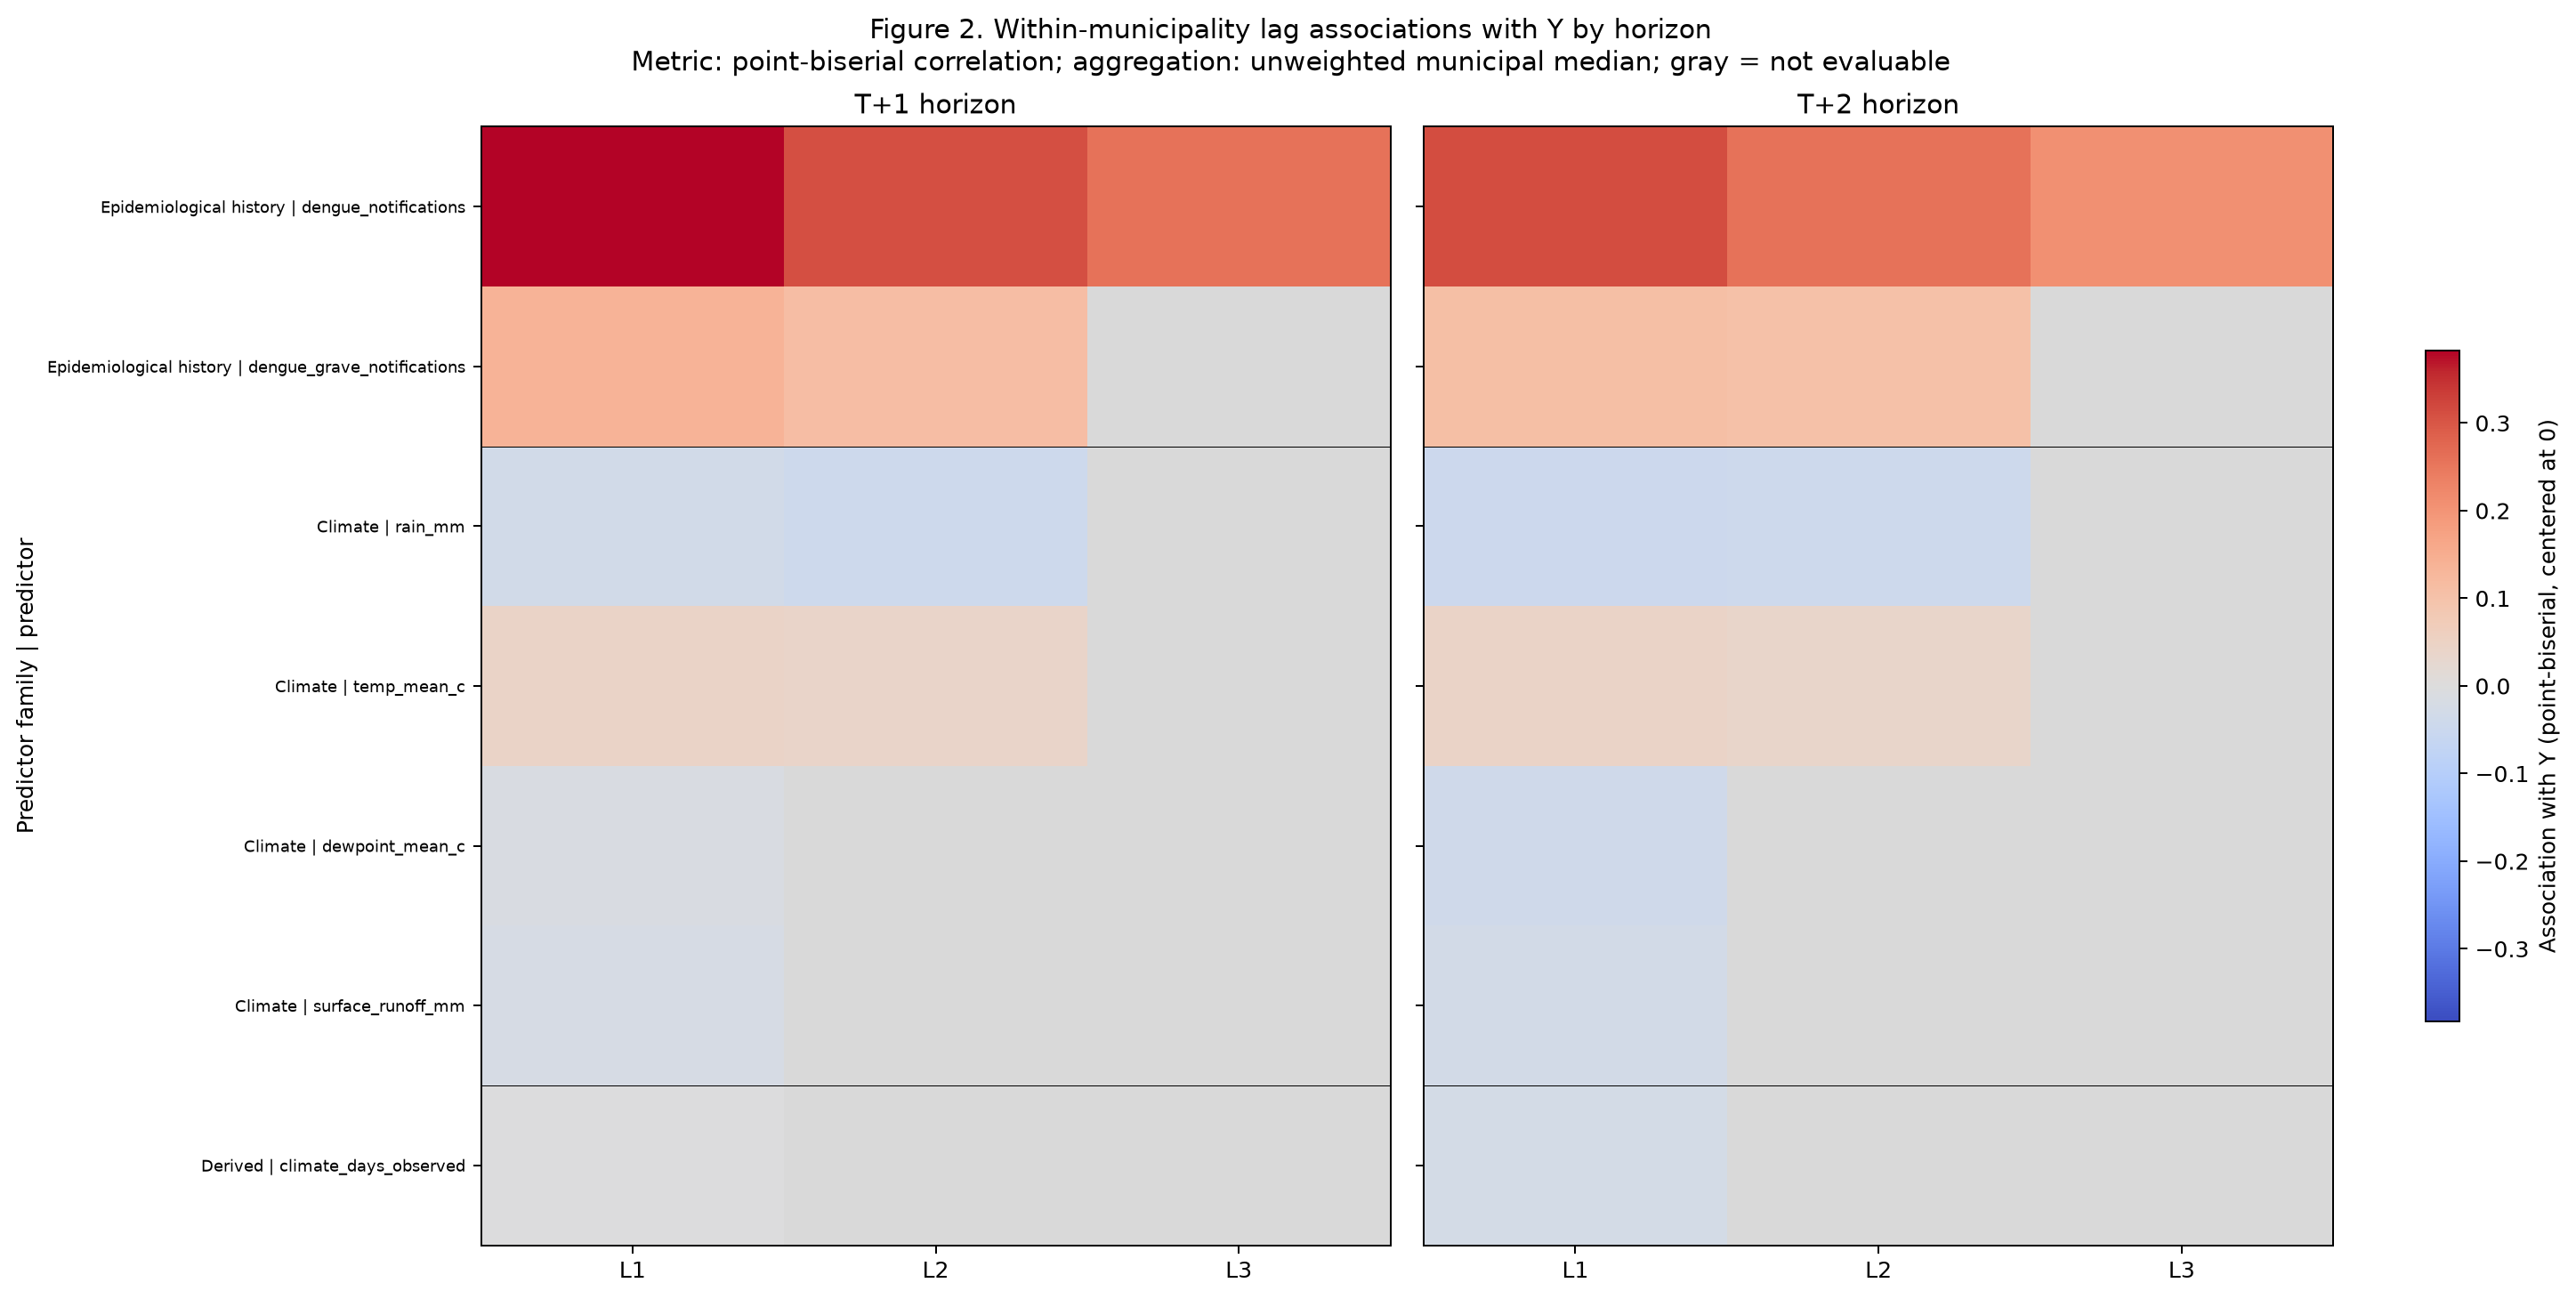

{
  "aggregate_rows": 24,
  "detail_rows": 1824,
  "method": "point_biserial_within_municipality_unweighted_median",
  "support_summary": [
    {
      "horizon": "t1",
      "predictors_reported": 12,
      "municipalities_total_max": 76,
      "municipalities_evaluable_median": 76.0,
      "rows_used_total": 147928
    },
    {
      "horizon": "t2",
      "predictors_reported": 12,
      "municipalities_total_max": 76,
      "municipalities_evaluable_median": 76.0,
      "rows_used_total": 148830
    }
  ],
  "figure_outputs": [
    "tmp/stage2_y_reconciliation/chapter6_figure2_lag_associations.png",
    "tmp/stage2_y_reconciliation/chapter6_figure2_lag_associations.svg"
  ],
  "note": "Associations are descriptive and do not imply causality, selection, or predictive superiority."
}


In [61]:
# Chapter 6 - Relationships with Y and lag diagnostics by horizon
association_aggregate, association_detail, association_meta = visual_assets.compute_lag_association_summary(
    panel_development,
    predictor_specs,
    min_rows_per_municipality=12,
)

association_aggregate.to_csv(ANALYSIS_DIR / "chapter6_lag_relationships.csv", index=False)
association_detail.to_csv(ANALYSIS_DIR / "chapter6_lag_associations_detail.csv", index=False)
(ANALYSIS_DIR / "chapter6_lag_associations_meta.json").write_text(
    json.dumps(association_meta, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

row_labels = []
for spec in predictor_specs:
    label = f"{spec.family} | {spec.display_name}"
    if label not in row_labels:
        row_labels.append(label)

lag_labels = sorted(
    {f"L{int(lag)}" for spec in predictor_specs for lag in spec.lags},
    key=lambda value: int(value[1:]),
)

def build_horizon_matrix(horizon: str) -> pd.DataFrame:
    subset = association_aggregate[association_aggregate["horizon"] == horizon].copy()
    subset["row_label"] = subset["family"] + " | " + subset["predictor"]
    subset["lag_label"] = subset["lag_months"].map(lambda value: f"L{int(value)}")
    matrix = subset.pivot_table(
        index="row_label",
        columns="lag_label",
        values="association_point_biserial_median",
        aggfunc="first",
    )
    return matrix.reindex(index=row_labels, columns=lag_labels)

matrix_t1 = build_horizon_matrix("t1")
matrix_t2 = build_horizon_matrix("t2")

all_values = np.concatenate(
    [
        matrix_t1.to_numpy(dtype=float).ravel(),
        matrix_t2.to_numpy(dtype=float).ravel(),
    ]
)
finite_values = all_values[np.isfinite(all_values)]
if finite_values.size == 0:
    vmax = 1.0
else:
    vmax = float(np.max(np.abs(finite_values)))
    if vmax == 0.0:
        vmax = 1.0

family_boundaries = []
family_names = [label.split(" | ")[0] for label in row_labels]
for idx in range(1, len(family_names)):
    if family_names[idx] != family_names[idx - 1]:
        family_boundaries.append(idx - 0.5)

# Presentation Figure 2 - Lag associations with Y(T+1/T+2) using within-municipality point-biserial summaries
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, max(8.0, 0.27 * len(row_labels))),
    dpi=180,
    sharey=True,
    constrained_layout=True,
)
for axis, matrix, horizon_label in [
    (axes[0], matrix_t1, "T+1"),
    (axes[1], matrix_t2, "T+2"),
]:
    masked = np.ma.masked_invalid(matrix.to_numpy(dtype=float))
    cmap = plt.colormaps["coolwarm"].copy()
    cmap.set_bad("#d9d9d9")
    image = axis.imshow(
        masked,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        vmin=-vmax,
        vmax=vmax,
    )
    axis.set_xticks(np.arange(len(matrix.columns)))
    axis.set_xticklabels(matrix.columns)
    axis.set_title(f"{horizon_label} horizon")
    for boundary in family_boundaries:
        axis.axhline(boundary, color="black", linewidth=0.4)

axes[0].set_yticks(np.arange(len(row_labels)))
axes[0].set_yticklabels(row_labels, fontsize=7)
axes[0].set_ylabel("Predictor family | predictor")
axes[1].set_yticks(np.arange(len(row_labels)))
axes[1].set_yticklabels(row_labels, fontsize=7)

fig.suptitle(
    "Figure 2. Within-municipality lag associations with Y by horizon\n"
    "Metric: point-biserial correlation; aggregation: unweighted municipal median; gray = not evaluable"
)

colorbar = fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.6)
colorbar.set_label("Association with Y (point-biserial, centered at 0)")

figure2_png = ANALYSIS_DIR / "chapter6_figure2_lag_associations.png"
figure2_svg = ANALYSIS_DIR / "chapter6_figure2_lag_associations.svg"
fig.savefig(figure2_png, dpi=220)
fig.savefig(figure2_svg)
plt.show()
plt.close(fig)

support_summary = (
    association_aggregate.groupby("horizon", as_index=False)
    .agg(
        predictors_reported=("predictor", "count"),
        municipalities_total_max=("municipalities_total", "max"),
        municipalities_evaluable_median=("municipalities_evaluable", "median"),
        rows_used_total=("rows_used_total", "sum"),
    )
    .to_dict(orient="records")
)

chapter6_summary = {
    "aggregate_rows": int(len(association_aggregate)),
    "detail_rows": int(len(association_detail)),
    "method": association_meta["method"],
    "support_summary": support_summary,
    "figure_outputs": [
        str(figure2_png.relative_to(ROOT)),
        str(figure2_svg.relative_to(ROOT)),
    ],
    "note": "Associations are descriptive and do not imply causality, selection, or predictive superiority.",
}

(ANALYSIS_DIR / "chapter6_summary.json").write_text(
    json.dumps(chapter6_summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(chapter6_summary, indent=2, ensure_ascii=False))

In [62]:
# Chapter 7 - Correlation and multicollinearity diagnostics
correlation_features = [
    "dengue_notifications_count",
    "dengue_grave_notifications_count",
    "rain_mm_month_sum",
    "temp_mean_c_month_mean",
    "dewpoint_mean_c_month_mean",
    "surface_runoff_mm_month_sum",
    "p75_t1",
    "p75_t2",
]

corr_data = panel_development[correlation_features].apply(pd.to_numeric, errors="coerce")
raw_correlation = corr_data.corr(method="spearman", min_periods=60)

adjusted = panel_development.copy()
adjusted["calendar_month"] = adjusted["year_month"].str.slice(5, 7)
for feature in correlation_features:
    if feature not in adjusted.columns:
        continue
    adjusted[feature] = pd.to_numeric(adjusted[feature], errors="coerce")
    adjusted[feature] = adjusted[feature] - adjusted.groupby("calendar_month")[feature].transform("mean")

adjusted_correlation = adjusted[correlation_features].corr(method="spearman", min_periods=60)

redundancy_rows = []
for i, left in enumerate(correlation_features):
    for right in correlation_features[i + 1 :]:
        value = raw_correlation.loc[left, right]
        if pd.isna(value):
            continue
        if abs(float(value)) >= 0.90:
            redundancy_rows.append(
                {
                    "feature_left": left,
                    "feature_right": right,
                    "spearman_raw": float(value),
                    "spearman_month_adjusted": float(adjusted_correlation.loc[left, right]),
                    "recommendation": "candidate_ablation_pair_review",
                }
            )

redundancy_groups = pd.DataFrame(redundancy_rows)

raw_correlation.to_csv(ANALYSIS_DIR / "chapter7_correlation_matrix_raw.csv")
adjusted_correlation.to_csv(ANALYSIS_DIR / "chapter7_correlation_matrix_month_adjusted.csv")
redundancy_groups.to_csv(ANALYSIS_DIR / "chapter7_correlation_groups.csv", index=False)

chapter7_summary = {
    "feature_count": len(correlation_features),
    "redundant_pairs_abs_ge_0_90": int(len(redundancy_groups)),
    "note": (
        "Correlation is interpreted with municipality and seasonal context; no automatic feature "
        "deletion is performed in this stage."
    ),
}

(ANALYSIS_DIR / "chapter7_summary.json").write_text(
    json.dumps(chapter7_summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(chapter7_summary, indent=2, ensure_ascii=False))

{
  "feature_count": 8,
  "redundant_pairs_abs_ge_0_90": 0,
  "note": "Correlation is interpreted with municipality and seasonal context; no automatic feature deletion is performed in this stage."
}


In [63]:
# Chapter 8 - Temporal validation protocol structure
window_train_endpoints = ["2018-12", "2020-12", "2022-12", "2024-06"]

protocol_rows = []
for train_end in window_train_endpoints:
    train_scope = panel_development[panel_development["year_month"] <= train_end]
    if train_scope.empty:
        continue

    validation_start = pipeline.add_months(train_end, 1)
    validation_end = pipeline.add_months(train_end, 6)

    protocol_rows.append(
        {
            "window_id": f"window_until_{train_end}",
            "train_start": str(panel_development["year_month"].min()),
            "train_end": train_end,
            "validation_start": validation_start,
            "validation_end": validation_end,
            "horizons": "t1_and_t2",
            "label_observability_rule": (
                "Use only rows where target-period observations are observable at simulated cutoff"
            ),
            "predictor_rule": "Predictors must use information available at cutoff T",
            "transformation_rule": "Fit transformations only on train split, then apply to validation split",
        }
    )

protocol_table = pd.DataFrame(protocol_rows)

audit_table = visual_assets.build_temporal_validation_audit(
    panel_development,
    panel_reserved,
    window_train_endpoints=window_train_endpoints,
    predictor_columns_used=predictor_columns_used,
)

# Presentation Table 2 - Temporal validation audit by protocol window
table2_columns = [
    "window_id",
    "horizon",
    "train_start",
    "train_end",
    "validation_start",
    "validation_end",
    "last_train_target_period_t1",
    "last_train_target_period_t2",
    "train_rows",
    "train_municipalities",
    "validation_rows",
    "validation_municipalities",
    "temporal_validation_result",
    "reason_if_not_pass",
]
display(audit_table[table2_columns].copy())

print(
    "Table 2 status note: each PASS/FAIL result comes from executed checks in this cell. "
    "Transformation fit checks are reported separately as NOT_EXECUTED when no fitted transformer exists in scope."
)

reserved_months = sorted(panel_reserved["year_month"].unique())
protocol_config = {
    "split_strategy": "shared_date_cutoffs_across_all_municipalities",
    "random_split_allowed": False,
    "reserved_block": {
        "start": reserved_months[0] if reserved_months else None,
        "end": reserved_months[-1] if reserved_months else None,
        "rows": int(len(panel_reserved)),
    },
    "rolling_windows": protocol_rows,
    "audit_summary": {
        "windows_audited": int(len(audit_table)),
        "windows_pass": int((audit_table["temporal_validation_result"] == "PASS").sum()),
        "windows_fail": int((audit_table["temporal_validation_result"] == "FAIL").sum()),
    },
    "retrospective_limit": (
        "Consolidated retrospective snapshots do not prove historical as-of publication versions."
    ),
}

protocol_table.to_csv(ANALYSIS_DIR / "chapter8_temporal_protocol_windows.csv", index=False)
audit_table.to_csv(ANALYSIS_DIR / "chapter8_table2_temporal_validation_audit.csv", index=False)
(ANALYSIS_DIR / "chapter8_temporal_protocol.json").write_text(
    json.dumps(protocol_config, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

print(json.dumps(protocol_config, indent=2, ensure_ascii=False))

,window_id,horizon,train_start,train_end,validation_start,validation_end,last_train_target_period_t1,last_train_target_period_t2,train_rows,train_municipalities,validation_rows,validation_municipalities,temporal_validation_result,reason_if_not_pass
0,window_until_2018-12,t1_and_t2,2006-06,2018-12,2019-01,2019-06,2019-01,2019-02,11476,76,456,76,FAIL,labels_not_observable_at_cutoff:t1:76|t2:152
1,window_until_2020-12,t1_and_t2,2006-06,2020-12,2021-01,2021-06,2021-01,2021-02,13300,76,456,76,FAIL,labels_not_observable_at_cutoff:t1:76|t2:152
2,window_until_2022-12,t1_and_t2,2006-06,2022-12,2023-01,2023-06,2023-01,2023-02,15124,76,456,76,FAIL,labels_not_observable_at_cutoff:t1:76|t2:152
3,window_until_2024-06,t1_and_t2,2006-06,2024-06,2024-07,2024-12,2024-07,2024-08,16492,76,456,76,FAIL,labels_not_observable_at_cutoff:t1:76|t2:152


Table 2 status note: each PASS/FAIL result comes from executed checks in this cell. Transformation fit checks are reported separately as NOT_EXECUTED when no fitted transformer exists in scope.
{
  "split_strategy": "shared_date_cutoffs_across_all_municipalities",
  "random_split_allowed": false,
  "reserved_block": {
    "start": "2025-01",
    "end": "2026-01",
    "rows": 988
  },
  "rolling_windows": [
    {
      "window_id": "window_until_2018-12",
      "train_start": "2006-06",
      "train_end": "2018-12",
      "validation_start": "2019-01",
      "validation_end": "2019-06",
      "horizons": "t1_and_t2",
      "label_observability_rule": "Use only rows where target-period observations are observable at simulated cutoff",
      "predictor_rule": "Predictors must use information available at cutoff T",
      "transformation_rule": "Fit transformations only on train split, then apply to validation split"
    },
    {
      "window_id": "window_until_2020-12",
      "train_star

In [64]:
# Chapter 9 - Final temporal regression checks (November to January and edge cases)
def independent_percentile_type7(values: list[float], q: float) -> float:
    ordered = sorted(float(value) for value in values)
    if len(ordered) == 1:
        return ordered[0]
    rank = (len(ordered) - 1) * q
    lower = int(rank)
    upper = min(lower + 1, len(ordered) - 1)
    fraction = rank - lower
    if lower == upper:
        return ordered[lower]
    return ordered[lower] + fraction * (ordered[upper] - ordered[lower])


def independent_history_periods(target_period: str, history_years: int = 5) -> list[str]:
    target_year = int(target_period[:4])
    target_month = target_period[5:7]
    return [f"{year:04d}-{target_month}" for year in range(target_year - history_years, target_year)]


def build_panel_for_main_case(target_count: float) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "municipality_code": ["50001"] * 8,
            "year_month": [
                "2020-01",
                "2021-01",
                "2022-01",
                "2023-01",
                "2024-01",
                "2024-11",
                "2025-01",
                "2026-01",
            ],
            "dengue_notifications_count": [2.0, 3.0, 4.0, 5.0, 100.0, 0.0, target_count, 999.0],
        }
    )

main_case_panel = build_panel_for_main_case(5.0)
main_case_labeled, _main_trace = pipeline.compute_y_labels(main_case_panel)
main_case_row = main_case_labeled[main_case_labeled["year_month"] == "2024-11"].iloc[0]
main_case_history_values = [2.0, 3.0, 4.0, 5.0, 100.0]
main_case_p75 = independent_percentile_type7(main_case_history_values, 0.75)

checks: list[dict[str, object]] = []
checks.append(
    {
        "name": "november_to_january_main_case",
        "passed": bool(
            main_case_row["target_period_t2"] == "2025-01"
            and main_case_row["history_periods_used_t2"] == "2020-01|2021-01|2022-01|2023-01|2024-01"
            and float(main_case_row["p75_t2"]) == 5.0
            and int(main_case_row["y_t2"]) == 0
            and main_case_p75 == 5.0
        ),
    }
)

nov_to_dec_panel = pd.DataFrame(
    {
        "municipality_code": ["50001"] * 7,
        "year_month": ["2019-12", "2020-12", "2021-12", "2022-12", "2023-12", "2024-11", "2024-12"],
        "dengue_notifications_count": [1.0, 2.0, 3.0, 4.0, 5.0, 0.0, 6.0],
    }
)
nov_to_dec_labeled, _ = pipeline.compute_y_labels(nov_to_dec_panel)
nov_to_dec_row = nov_to_dec_labeled[nov_to_dec_labeled["year_month"] == "2024-11"].iloc[0]
checks.append(
    {
        "name": "november_to_december",
        "passed": bool(
            nov_to_dec_row["target_period_t1"] == "2024-12"
            and nov_to_dec_row["history_periods_used_t1"] == "2019-12|2020-12|2021-12|2022-12|2023-12"
        ),
    }
)

dec_cross_panel = pd.DataFrame(
    {
        "municipality_code": ["50001"] * 13,
        "year_month": [
            "2020-01",
            "2021-01",
            "2022-01",
            "2023-01",
            "2024-01",
            "2020-02",
            "2021-02",
            "2022-02",
            "2023-02",
            "2024-02",
            "2024-12",
            "2025-01",
            "2025-02",
        ],
        "dengue_notifications_count": [2.0, 3.0, 4.0, 5.0, 6.0, 1.0, 1.0, 2.0, 2.0, 3.0, 0.0, 4.0, 3.0],
    }
)
dec_cross_labeled, _ = pipeline.compute_y_labels(dec_cross_panel)
dec_cross_row = dec_cross_labeled[dec_cross_labeled["year_month"] == "2024-12"].iloc[0]
checks.append(
    {
        "name": "december_to_january_and_february",
        "passed": bool(
            dec_cross_row["target_period_t1"] == "2025-01"
            and dec_cross_row["target_period_t2"] == "2025-02"
        ),
    }
)

all_month_rows = []
for month in range(1, 13):
    for year in range(2019, 2027):
        all_month_rows.append(
            {
                "municipality_code": "50001",
                "year_month": f"{year:04d}-{month:02d}",
                "dengue_notifications_count": float((year - 2018) + month),
            }
        )
all_month_panel = pd.DataFrame(all_month_rows).drop_duplicates(["municipality_code", "year_month"])
all_month_labeled, _ = pipeline.compute_y_labels(all_month_panel)
all_month_pass = True
for month in range(1, 13):
    cutoff = f"2024-{month:02d}"
    row = all_month_labeled[all_month_labeled["year_month"] == cutoff].iloc[0]
    for horizon in (1, 2):
        suffix = f"t{horizon}"
        target_period = str(row[f"target_period_{suffix}"])
        expected = "|".join(independent_history_periods(target_period, 5))
        if row[f"history_periods_expected_{suffix}"] != expected:
            all_month_pass = False
checks.append({"name": "all_cutoff_months_both_horizons", "passed": all_month_pass})

main_case_variant = build_panel_for_main_case(50.0)
variant_labeled, _ = pipeline.compute_y_labels(main_case_variant)
variant_row = variant_labeled[variant_labeled["year_month"] == "2024-11"].iloc[0]
checks.append(
    {
        "name": "target_count_change_does_not_change_threshold",
        "passed": bool(float(main_case_row["p75_t2"]) == float(variant_row["p75_t2"])),
    }
)

missing_history_panel = pd.DataFrame(
    {
        "municipality_code": ["50001"] * 8,
        "year_month": ["2018-01", "2019-01", "2020-01", "2021-01", "2023-01", "2024-01", "2024-11", "2025-01"],
        "dengue_notifications_count": [99.0, 1.0, 2.0, 3.0, 5.0, 100.0, 0.0, 5.0],
    }
)
missing_history_labeled, _ = pipeline.compute_y_labels(missing_history_panel)
missing_history_row = missing_history_labeled[missing_history_labeled["year_month"] == "2024-11"].iloc[0]
checks.append(
    {
        "name": "missing_history_no_silent_substitution",
        "passed": bool(
            missing_history_row["history_periods_expected_t2"]
            == "2020-01|2021-01|2022-01|2023-01|2024-01"
            and missing_history_row["history_missing_periods_t2"] == "2022-01"
            and missing_history_row["y_status_t2"] == "insufficient_history"
        ),
    }
)

independence_panel = pd.DataFrame(
    {
        "municipality_code": ["50001", "50001", "50001", "50001", "50001", "50001", "50001", "50002", "50002", "50002", "50002", "50002", "50002", "50002"],
        "year_month": ["2020-01", "2021-01", "2022-01", "2023-01", "2024-01", "2024-11", "2025-01", "2020-01", "2021-01", "2022-01", "2023-01", "2024-01", "2024-11", "2025-01"],
        "dengue_notifications_count": [2.0, 3.0, 4.0, 5.0, 100.0, 0.0, 5.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0],
    }
)
independence_labeled, _ = pipeline.compute_y_labels(independence_panel)
row_a = independence_labeled[
    (independence_labeled["municipality_code"] == "50001")
    & (independence_labeled["year_month"] == "2024-11")
].iloc[0]
row_b = independence_labeled[
    (independence_labeled["municipality_code"] == "50002")
    & (independence_labeled["year_month"] == "2024-11")
].iloc[0]
checks.append(
    {
        "name": "municipality_independence",
        "passed": bool(float(row_a["p75_t2"]) != float(row_b["p75_t2"])),
    }
)

passed = [item for item in checks if bool(item["passed"])]
failed = [item for item in checks if not bool(item["passed"])]

regression_payload = {
    "november_to_january_case": {
        "history_periods": ["2020-01", "2021-01", "2022-01", "2023-01", "2024-01"],
        "history_values": main_case_history_values,
        "p75": main_case_p75,
        "target_observed": 5.0,
        "y_expected": 0,
        "pipeline_p75": float(main_case_row["p75_t2"]),
        "pipeline_y": int(main_case_row["y_t2"]),
    },
    "checks": checks,
    "passed_checks": len(passed),
    "failed_checks": len(failed),
}

if failed:
    raise RuntimeError(f"Temporal regression checks failed: {failed}")

(ANALYSIS_DIR / "chapter9_temporal_regression_checks.json").write_text(
    json.dumps(regression_payload, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

conclusion_matrix = pd.DataFrame(
    [
        {
            "finding": "Y reference uses same month from five prior years",
            "evidence": "Chapter 9 synthetic checks and pipeline traceability columns",
            "implication_for_v1": "V1 channel comparisons must preserve same-month yearly references",
            "proposed_adjustment": "Keep strict same-month historical lookup and avoid silent year substitution",
            "pending_comparison": "Model-family comparison with aligned windows and metrics",
        },
        {
            "finding": "Non-evaluable Y remains null when required history is genuinely missing",
            "evidence": "Insufficient-history regression check",
            "implication_for_v1": "Do not coerce unresolved labels to zero during training-set assembly",
            "proposed_adjustment": "Filter or model missingness explicitly in downstream tasks",
            "pending_comparison": "Impact on PR-AUC and calibration by municipality",
        },
        {
            "finding": "Temporal protocol requires shared cutoffs and reserved final block",
            "evidence": "Chapter 8 protocol artifact",
            "implication_for_v1": "Random splits are not comparable with horizon-aware deployment",
            "proposed_adjustment": "Use rolling windows with horizon-aligned observability constraints",
            "pending_comparison": "False alarms and onset detection per horizon",
        },
    ]
)
conclusion_matrix.to_csv(ANALYSIS_DIR / "chapter9_conclusion_matrix.csv", index=False)

print(json.dumps(regression_payload, indent=2, ensure_ascii=False))

{
  "november_to_january_case": {
    "history_periods": [
      "2020-01",
      "2021-01",
      "2022-01",
      "2023-01",
      "2024-01"
    ],
    "history_values": [
      2.0,
      3.0,
      4.0,
      5.0,
      100.0
    ],
    "p75": 5.0,
    "target_observed": 5.0,
    "y_expected": 0,
    "pipeline_p75": 5.0,
    "pipeline_y": 0
  },
  "checks": [
    {
      "name": "november_to_january_main_case",
      "passed": true
    },
    {
      "name": "november_to_december",
      "passed": true
    },
    {
      "name": "december_to_january_and_february",
      "passed": true
    },
    {
      "name": "all_cutoff_months_both_horizons",
      "passed": true
    },
    {
      "name": "target_count_change_does_not_change_threshold",
      "passed": true
    },
    {
      "name": "missing_history_no_silent_substitution",
      "passed": true
    },
    {
      "name": "municipality_independence",
      "passed": true
    }
  ],
  "passed_checks": 7,
  "failed_checks": 0
}


In [65]:
# Chapter 10 - Analysis manifest and scope validator
def hash_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

analysis_files = sorted(
    [
        path
        for path in ANALYSIS_DIR.glob("*")
        if path.is_file() and path.name != "notebook_analysis_manifest.json"
    ]
)

resource_manifest = {
    "table_1_missingness_continuity": {
        "chapter": "Chapter 3",
        "display_source": "tmp/stage2_y_reconciliation/chapter3_table1_missingness_compact.csv",
        "full_inventory": "tmp/stage2_y_reconciliation/chapter3_missingness_summary.csv",
        "denominators": "tmp/stage2_y_reconciliation/chapter3_missingness_denominators.json",
        "period": {
            "development_start": chapter2_summary["development_start"],
            "development_end": chapter2_summary["development_end"],
        },
        "config": {
            "top_k": 10,
            "selection_rule": "impact_score_desc_missing_rows_desc_variable_asc",
        },
    },
    "figure_1_municipality_seasonality": {
        "chapter": "Chapter 4",
        "figure_png": "tmp/stage2_y_reconciliation/chapter4_figure1_municipality_seasonality.png",
        "figure_svg": "tmp/stage2_y_reconciliation/chapter4_figure1_municipality_seasonality.svg",
        "raw_profile": "tmp/stage2_y_reconciliation/chapter4_seasonality_profile_raw.csv",
        "support": "tmp/stage2_y_reconciliation/chapter4_seasonality_support.csv",
        "metadata": "tmp/stage2_y_reconciliation/chapter4_seasonality_meta.json",
        "period": {
            "development_start": chapter2_summary["development_start"],
            "development_end": chapter2_summary["development_end"],
        },
        "config": {
            "normalization": "within_municipality_minmax_with_constant_handling",
            "constant_nonzero_value": 0.5,
        },
    },
    "figure_2_lag_associations": {
        "chapter": "Chapter 6",
        "figure_png": "tmp/stage2_y_reconciliation/chapter6_figure2_lag_associations.png",
        "figure_svg": "tmp/stage2_y_reconciliation/chapter6_figure2_lag_associations.svg",
        "aggregate": "tmp/stage2_y_reconciliation/chapter6_lag_relationships.csv",
        "detail": "tmp/stage2_y_reconciliation/chapter6_lag_associations_detail.csv",
        "metadata": "tmp/stage2_y_reconciliation/chapter6_lag_associations_meta.json",
        "period": {
            "development_start": chapter2_summary["development_start"],
            "development_end": chapter2_summary["development_end"],
        },
        "config": {
            "association_method": "point_biserial_within_municipality_unweighted_median",
            "minimum_rows_per_municipality": 12,
        },
    },
    "table_2_temporal_validation_audit": {
        "chapter": "Chapter 8",
        "display_source": "tmp/stage2_y_reconciliation/chapter8_table2_temporal_validation_audit.csv",
        "protocol_windows": "tmp/stage2_y_reconciliation/chapter8_temporal_protocol_windows.csv",
        "protocol_json": "tmp/stage2_y_reconciliation/chapter8_temporal_protocol.json",
        "period": {
            "development_start": chapter2_summary["development_start"],
            "development_end": chapter2_summary["development_end"],
            "reserved_block_start": chapter2_summary["reserved_block_start"],
            "reserved_block_end": chapter2_summary["reserved_block_end"],
        },
        "config": {
            "window_train_endpoints": ["2018-12", "2020-12", "2022-12", "2024-06"],
            "horizon": "t1_and_t2",
        },
    },
}

analysis_manifest = {
    "generated_utc": pipeline.utc_now_iso(),
    "analysis_dir": str(ANALYSIS_DIR.relative_to(ROOT)),
    "input_panel": "data/processed/panel_mensual_dengue_clima.csv",
    "files": [
        {
            "path": str(path.relative_to(ROOT)),
            "bytes": path.stat().st_size,
            "sha256": hash_file(path),
        }
        for path in analysis_files
    ],
    "chapter_count_added": 7,
    "presentation_assets": {
        "tables": 2,
        "figures": 2,
    },
    "resource_manifest": resource_manifest,
    "notes": {
        "temporal_protocol": "retrospective descriptive stage only",
        "model_training": "not_executed",
    },
}

manifest_out = ANALYSIS_DIR / "notebook_analysis_manifest.json"
manifest_out.write_text(
    json.dumps(analysis_manifest, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

scope_validator_path = ROOT / ".dwp/plans/PLAN_015_stage2_y_reconciliation/validate_scope_outputs.py"
spec = importlib.util.spec_from_file_location("scope_validator", scope_validator_path)
if spec is None or spec.loader is None:
    raise RuntimeError("Unable to load PLAN_015 scope validator")
scope_validator = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = scope_validator
spec.loader.exec_module(scope_validator)
scope_report = scope_validator.validate_quick(ROOT, pipeline)

print(json.dumps({"analysis_manifest": analysis_manifest, "scope_report": scope_report}, indent=2))

{
  "analysis_manifest": {
    "generated_utc": "2026-10-19T15:32:35.484566+00:00",
    "analysis_dir": "tmp/stage2_y_reconciliation",
    "input_panel": "data/processed/panel_mensual_dengue_clima.csv",
    "files": [
      {
        "path": "tmp/stage2_y_reconciliation/chapter2_temporal_preparation.json",
        "bytes": 545,
        "sha256": "2b59640a5c4526e84d60478560f0c5d79f30955eb893080833475e655c0bfd3a"
      },
      {
        "path": "tmp/stage2_y_reconciliation/chapter3_missingness_denominators.json",
        "bytes": 2639,
        "sha256": "4975112038fe811c46c20dea58aa829e6c574ddd1b52a3fdf759b6f67618d027"
      },
      {
        "path": "tmp/stage2_y_reconciliation/chapter3_missingness_proposals.csv",
        "bytes": 809,
        "sha256": "5060a1ed24fdbfd99d5e8df0f99bb7ddd0b845777c98bdc04df0920d4ef4c454"
      },
      {
        "path": "tmp/stage2_y_reconciliation/chapter3_missingness_summary.csv",
        "bytes": 1867,
        "sha256": "a5a842ca585a8295d3883fd85970c